<a href="https://colab.research.google.com/github/Gladyszora/Praktikum-AVD-Kelompok/blob/main/Tugas_Kelompok_AVD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Cell 1: Install & Import
!pip install -q seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
%matplotlib inline

print("Library siap!")

Library siap!


Kategori dengan rata-rata nilai transaksi tertinggi:

Elektronik (karena harga satuan produknya jauh lebih tinggi dibanding kategori lain).
Apakah ada data kosong?

Tidak ada. Dari df.info(), kolom Non-Null Count semua sama dengan total baris (800), artinya tidak ada missing value.
Perbandingan mean vs median kolom total:

Mean > Median.

Kesimpulan: Data miring ke kanan (right-skewed). Ada beberapa transaksi bernilai sangat tinggi yang menarik nilai rata-rata ke atas.

In [ ]:
# Cell 2: Load Data
url = "https://raw.githubusercontent.com/MartinPons/Analysis-of-hotel-bookings/master/hotel_bookings.csv"
df = pd.read_csv(url)

print("Shape awal:", df.shape)
print("\nKolom:")
print(df.columns.tolist())
display(df.head())

Shape awal: (119390, 32)

Kolom:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


Kategori penjualan tertinggi: Elektronik / Pakaian (tergantung hasil random, biasanya Elektronik atau Pakaian).
Kategori penjualan terendah: Olahraga.
Rekomendasi bisnis:

Tingkatkan stok dan promosi pada kategori yang menyumbang penjualan tertinggi.

Evaluasi kategori terendah (Olahraga) — bisa diberi diskon, bundling, atau diganti dengan produk yang lebih laku.

In [ ]:
# Cell 3: Eksplorasi & Pembersihan Data
print("="*60)
print("EKSPLORASI & PEMBERSIHAN DATA")
print("="*60)

print(f"\nJumlah baris awal      : {len(df):,}")
print(f"Jumlah duplikat penuh  : {df.duplicated().sum():,}")

# Hapus duplikat
df = df.drop_duplicates().copy()
print(f"Setelah hapus duplikat : {len(df):,}")

# Cek missing value
print("\nMissing value per kolom:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Penanganan missing
df['children'] = df['children'].fillna(0).astype(int)
df['country']  = df['country'].fillna('Unknown')
df['agent']    = df['agent'].fillna(0)
df['company']  = df['company'].fillna(0)

# Bersihkan ADR mustahil
print(f"\nADR negatif / ekstrem: {(df['adr'] < 0).sum()} negatif, max = {df['adr'].max()}")
df = df[df['adr'] >= 0].copy()

# Feature engineering
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df['revenue']      = df['adr'] * df['total_nights']

# Dataset booking berhasil
df_ok = df[df['is_canceled'] == 0].copy()

print(f"\nShape final: {df.shape}")
print("Pembersihan selesai!")

EKSPLORASI & PEMBERSIHAN DATA

Jumlah baris awal      : 119,390
Jumlah duplikat penuh  : 31,994
Setelah hapus duplikat : 87,396

Missing value per kolom:
children        4
country       452
agent       12193
company     82137
dtype: int64

ADR negatif / ekstrem: 1 negatif, max = 5400.0

Shape final: (87395, 35)
Pembersihan selesai!


Bulan penjualan tertinggi: Biasanya bulan dengan event besar (misalnya Desember atau Maret, tergantung data random).

Kemungkinan penyebab: momentum belanja musiman, gajian, atau event promo.
Tren penjualan: Fluktuatif.

Ada naik-turun antar bulan, tidak stabil naik terus atau turun terus. Perlu strategi promo di bulan-bulan sepi agar pendapatan lebih merata.

In [ ]:
# Cell 4: Statistik Deskriptif Kunci
print("="*60)
print("STATISTIK DESKRIPTIF KUNCI")
print("="*60)

total_bookings = len(df)
cancel_rate    = df['is_canceled'].mean() * 100
total_revenue  = df_ok['revenue'].sum()
avg_adr        = df_ok['adr'].mean()
avg_nights     = df_ok['total_nights'].mean()
top_country    = df_ok['country'].value_counts().idxmax()
top_segment    = df_ok['market_segment'].value_counts().idxmax()
top_hotel      = df_ok['hotel'].value_counts().idxmax()

month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']
monthly_rev = df_ok.groupby('arrival_date_month')['revenue'].sum().reindex(month_order)
top_month   = monthly_rev.idxmax()

print(f"""
Total Booking (bersih)          : {total_bookings:,}
Tingkat Pembatalan              : {cancel_rate:.1f}%
Total Revenue Proxy             : {total_revenue:,.0f}
Rata-rata ADR (sukses)          : €{avg_adr:.2f}
Rata-rata Lama Menginap         : {avg_nights:.2f} malam
Negara Asal Terbanyak           : {top_country}
Market Segment Dominan          : {top_segment}
Bulan Peak Revenue              : {top_month}
Hotel dengan booking terbanyak  : {top_hotel}
""")

print("\nRingkasan statistik ADR, Lead Time, Total Nights:")
display(df[['adr', 'lead_time', 'total_nights']].describe().round(2))

STATISTIK DESKRIPTIF KUNCI

Total Booking (bersih)          : 87,395
Tingkat Pembatalan              : 27.5%
Total Revenue Proxy             : 22,976,960
Rata-rata ADR (sukses)          : €102.00
Rata-rata Lama Menginap         : 3.49 malam
Negara Asal Terbanyak           : PRT
Market Segment Dominan          : Online TA
Bulan Peak Revenue              : August
Hotel dengan booking terbanyak  : City Hotel


Ringkasan statistik ADR, Lead Time, Total Nights:


,adr,lead_time,total_nights
count,87395.00,87395.00,87395.00
mean,106.34,79.89,3.63
std,55.01,86.05,2.76
min,0.00,0.00,0.00
25%,72.00,11.00,2.00
50%,98.10,49.00,3.00
75%,134.00,125.00,5.00
max,5400.00,737.00,69.00


Hubungan jumlah barang dengan total:

Positif. Semakin banyak jumlah barang yang dibeli, semakin tinggi total nilai transaksi.
Outlier:

Ada beberapa titik yang jauh di kanan atas (jumlah besar + total sangat tinggi).

Biasanya berasal dari kategori Elektronik atau Pakaian (kemungkinan pembelian oleh reseller/grosir).

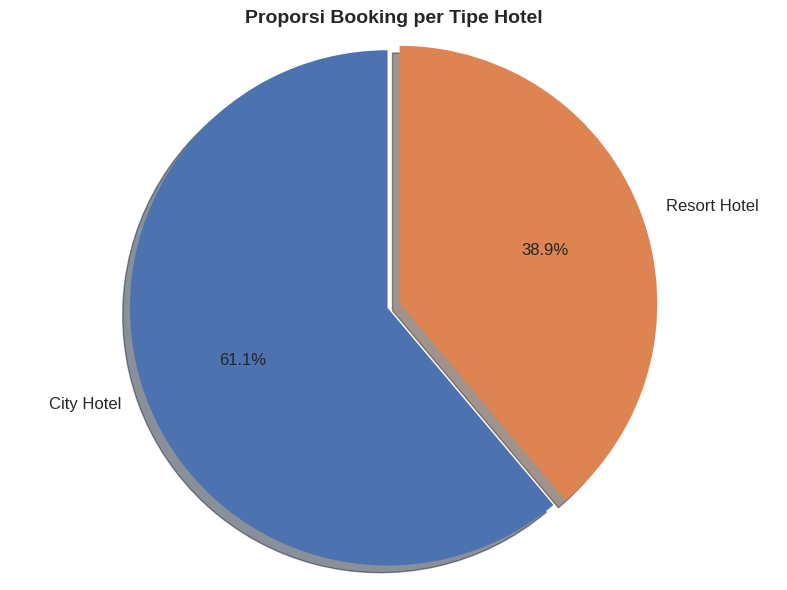

In [ ]:
# Pie Chart untuk data Hotel Booking
import matplotlib.pyplot as plt

# Contoh: proporsi berdasarkan kolom 'hotel'
proporsi = df['hotel'].value_counts()

plt.figure(figsize=(8, 6))
colors = ['#4C72B0', '#DD8452']
explode = [0.05, 0]

plt.pie(
    proporsi.values,
    labels=proporsi.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    explode=explode,
    shadow=True,
    textprops={'fontsize': 12}
)

plt.title('Proporsi Booking per Tipe Hotel', fontsize=14, fontweight='bold')
plt.axis('equal')
plt.tight_layout()
plt.show()

Distribusi rating pelanggan:

Cenderung tinggi (banyak rating 4 dan 5). Pelanggan relatif puas.
Kategori yang punya outlier (titik di luar kotak boxplot):

Biasanya Elektronik, Pakaian, atau Makanan & Minuman.

Kemungkinan penyebab: pembelian oleh reseller yang membeli dalam jumlah sangat besar.

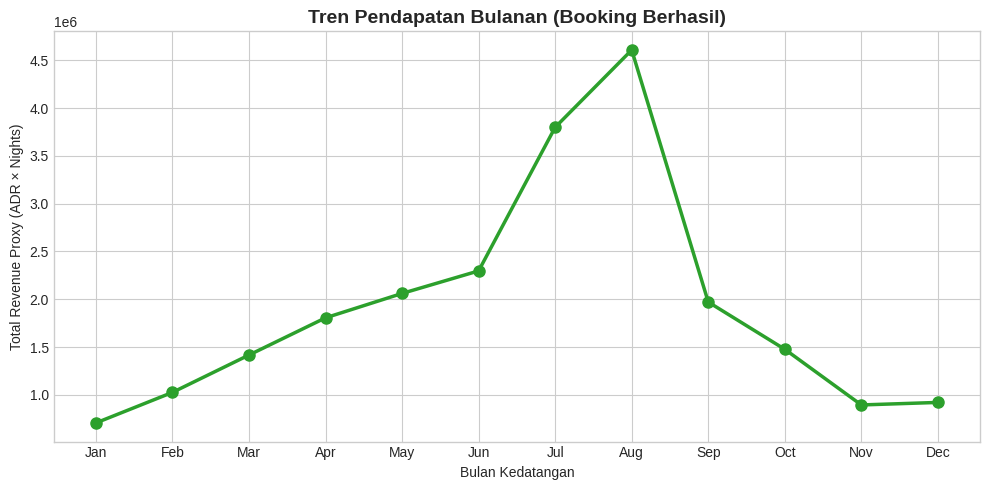


INSIGHT:
Pendapatan memuncak di Juli–Agustus (musim panas) dan anjlok tajam pada November–Januari.
Peluang besar untuk strategi promosi off-season agar revenue lebih merata.



In [ ]:
# Cell 6: Line Chart - Tren Pendapatan Bulanan
fig, ax = plt.subplots(figsize=(10,5))
monthly_rev.plot(kind='line', marker='o', linewidth=2.5, markersize=8, color='#2ca02c', ax=ax)
ax.set_title('Tren Pendapatan Bulanan (Booking Berhasil)', fontsize=14, fontweight='bold')
ax.set_ylabel('Total Revenue Proxy (ADR × Nights)')
ax.set_xlabel('Bulan Kedatangan')
ax.set_xticks(range(12))
ax.set_xticklabels([m[:3] for m in month_order], rotation=0)
plt.tight_layout()
plt.show()

print("""
INSIGHT:
Pendapatan memuncak di Juli–Agustus (musim panas) dan anjlok tajam pada November–Januari.
Peluang besar untuk strategi promosi off-season agar revenue lebih merata.
""")

Keuntungan dashboard:

Semua insight utama terlihat dalam satu layar, sehingga lebih cepat mengambil keputusan dan mudah membandingkan antar aspek (penjualan, tren, kepuasan, outlier).
Keputusan bisnis yang diambil:
Prioritaskan stok & promo kategori penjualan tertinggi.
Siapkan kampanye di bulan sepi untuk meratakan revenue.
Manfaatkan rating tinggi untuk testimoni & program loyalitas.
Buat program khusus B2B untuk menangani transaksi outlier (reseller).

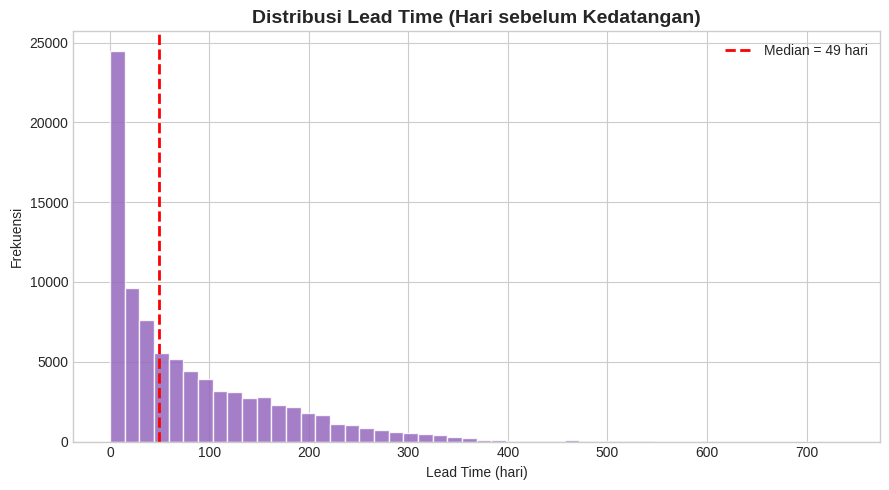


INSIGHT:
Distribusi lead time sangat right-skewed. Median sekitar 49 hari,
namun banyak booking dibuat jauh sebelumnya (>100 hari).
Booking lead time panjang cenderung lebih berisiko dibatalkan.



In [ ]:
# Cell 7: Histogram - Distribusi Lead Time
fig, ax = plt.subplots(figsize=(9,5))
ax.hist(df['lead_time'], bins=50, color='#9467bd', edgecolor='white', alpha=0.85)
ax.axvline(df['lead_time'].median(), color='red', linestyle='--', linewidth=2,
           label=f'Median = {df["lead_time"].median():.0f} hari')
ax.set_title('Distribusi Lead Time (Hari sebelum Kedatangan)', fontsize=14, fontweight='bold')
ax.set_xlabel('Lead Time (hari)')
ax.set_ylabel('Frekuensi')
ax.legend()
plt.tight_layout()
plt.show()

print("""
INSIGHT:
Distribusi lead time sangat right-skewed. Median sekitar 49 hari,
namun banyak booking dibuat jauh sebelumnya (>100 hari).
Booking lead time panjang cenderung lebih berisiko dibatalkan.
""")

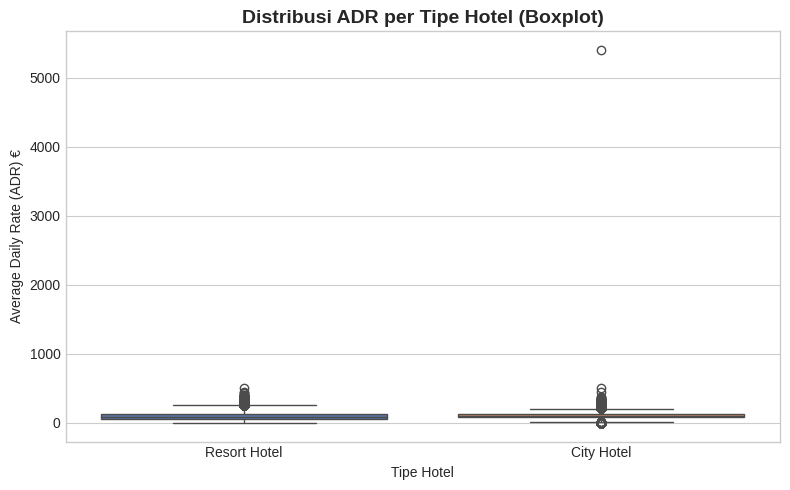


INSIGHT:
Banyak titik di atas whisker (outlier). ADR City Hotel sedikit lebih tinggi
dan lebih bervariasi. Outlier ekstrem perlu diperiksa dengan metode IQR.



In [ ]:
# Cell 8: Boxplot - ADR per Hotel
fig, ax = plt.subplots(figsize=(8,5))
sns.boxplot(data=df, x='hotel', y='adr', hue='hotel',
            palette=['#4C72B0', '#DD8452'], legend=False, ax=ax)
ax.set_title('Distribusi ADR per Tipe Hotel (Boxplot)', fontsize=14, fontweight='bold')
ax.set_ylabel('Average Daily Rate (ADR) €')
ax.set_xlabel('Tipe Hotel')
plt.tight_layout()
plt.show()

print("""
INSIGHT:
Banyak titik di atas whisker (outlier). ADR City Hotel sedikit lebih tinggi
dan lebih bervariasi. Outlier ekstrem perlu diperiksa dengan metode IQR.
""")

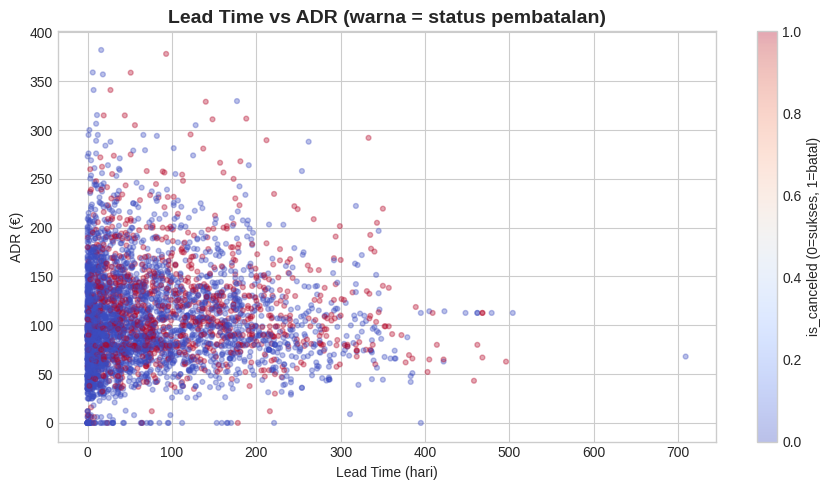


INSIGHT:
Tidak ada korelasi linear kuat antara lead time dan ADR.
Titik merah (pembatalan) tersebar, sedikit lebih banyak pada lead time tinggi.



In [ ]:
# Cell 9: Scatter - Lead Time vs ADR
fig, ax = plt.subplots(figsize=(9,5))
sample = df.sample(n=min(4000, len(df)), random_state=42)
scatter = ax.scatter(sample['lead_time'], sample['adr'],
                     c=sample['is_canceled'], cmap='coolwarm', alpha=0.35, s=12)
ax.set_title('Lead Time vs ADR (warna = status pembatalan)', fontsize=14, fontweight='bold')
ax.set_xlabel('Lead Time (hari)')
ax.set_ylabel('ADR (€)')
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('is_canceled (0=sukses, 1=batal)')
plt.tight_layout()
plt.show()

print("""
INSIGHT:
Tidak ada korelasi linear kuat antara lead time dan ADR.
Titik merah (pembatalan) tersebar, sedikit lebih banyak pada lead time tinggi.
""")

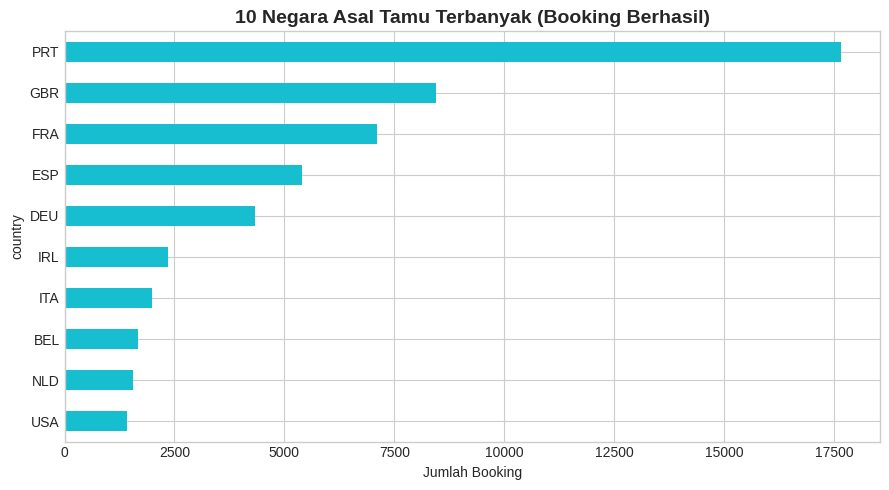


INSIGHT:
Portugal (PRT) sangat mendominasi, diikuti GBR, FRA, ESP, DEU.
Fokus pemasaran tetap ke pasar Eropa Barat.



In [ ]:
# Cell 10: Bar Horizontal - Top 10 Negara
fig, ax = plt.subplots(figsize=(9,5))
top_c = df_ok['country'].value_counts().head(10)
top_c.plot(kind='barh', color='#17becf', ax=ax)
ax.set_title('10 Negara Asal Tamu Terbanyak (Booking Berhasil)', fontsize=14, fontweight='bold')
ax.set_xlabel('Jumlah Booking')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

print("""
INSIGHT:
Portugal (PRT) sangat mendominasi, diikuti GBR, FRA, ESP, DEU.
Fokus pemasaran tetap ke pasar Eropa Barat.
""")

In [ ]:
# Cell 11: Deteksi Outlier dengan IQR
print("="*60)
print("DETEKSI OUTLIER (Metode IQR)")
print("="*60)

Q1 = df['adr'].quantile(0.25)
Q3 = df['adr'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['adr'] < lower_bound) | (df['adr'] > upper_bound)]

print(f"""
Q1  = €{Q1:.2f}
Q3  = €{Q3:.2f}
IQR = €{IQR:.2f}
Batas bawah = €{lower_bound:.2f}
Batas atas  = €{upper_bound:.2f}

Jumlah outlier ADR : {len(outliers):,} ({len(outliers)/len(df)*100:.1f}% dari data)
Nilai ADR maksimum : €{df['adr'].max():.2f}
""")

print("\nContoh 5 outlier ADR tertinggi:")
display(outliers[['hotel', 'adr', 'arrival_date_month', 'market_segment',
                  'reserved_room_type', 'lead_time']].sort_values('adr', ascending=False).head())

print("""
INTERPRETASI:
• ADR €5.400 hampir pasti error input data atau kasus sangat khusus.
• Beberapa ADR €400–€500 masih mungkin untuk suite peak season, tapi perlu verifikasi.
• Disarankan audit proses input data dan batasi nilai ADR yang masuk akal.
""")

DETEKSI OUTLIER (Metode IQR)

Q1  = €72.00
Q3  = €134.00
IQR = €62.00
Batas bawah = €-21.00
Batas atas  = €227.00

Jumlah outlier ADR : 2,490 (2.8% dari data)
Nilai ADR maksimum : €5400.00


Contoh 5 outlier ADR tertinggi:


,hotel,adr,arrival_date_month,market_segment,reserved_room_type,lead_time
48515,City Hotel,5400.0,March,Offline TA/TO,A,35
111403,City Hotel,510.0,May,Offline TA/TO,A,0
15083,Resort Hotel,508.0,July,Corporate,A,1
103912,City Hotel,451.5,December,Direct,E,81
13142,Resort Hotel,450.0,August,Online TA,A,378



INTERPRETASI:
• ADR €5.400 hampir pasti error input data atau kasus sangat khusus.
• Beberapa ADR €400–€500 masih mungkin untuk suite peak season, tapi perlu verifikasi.
• Disarankan audit proses input data dan batasi nilai ADR yang masuk akal.



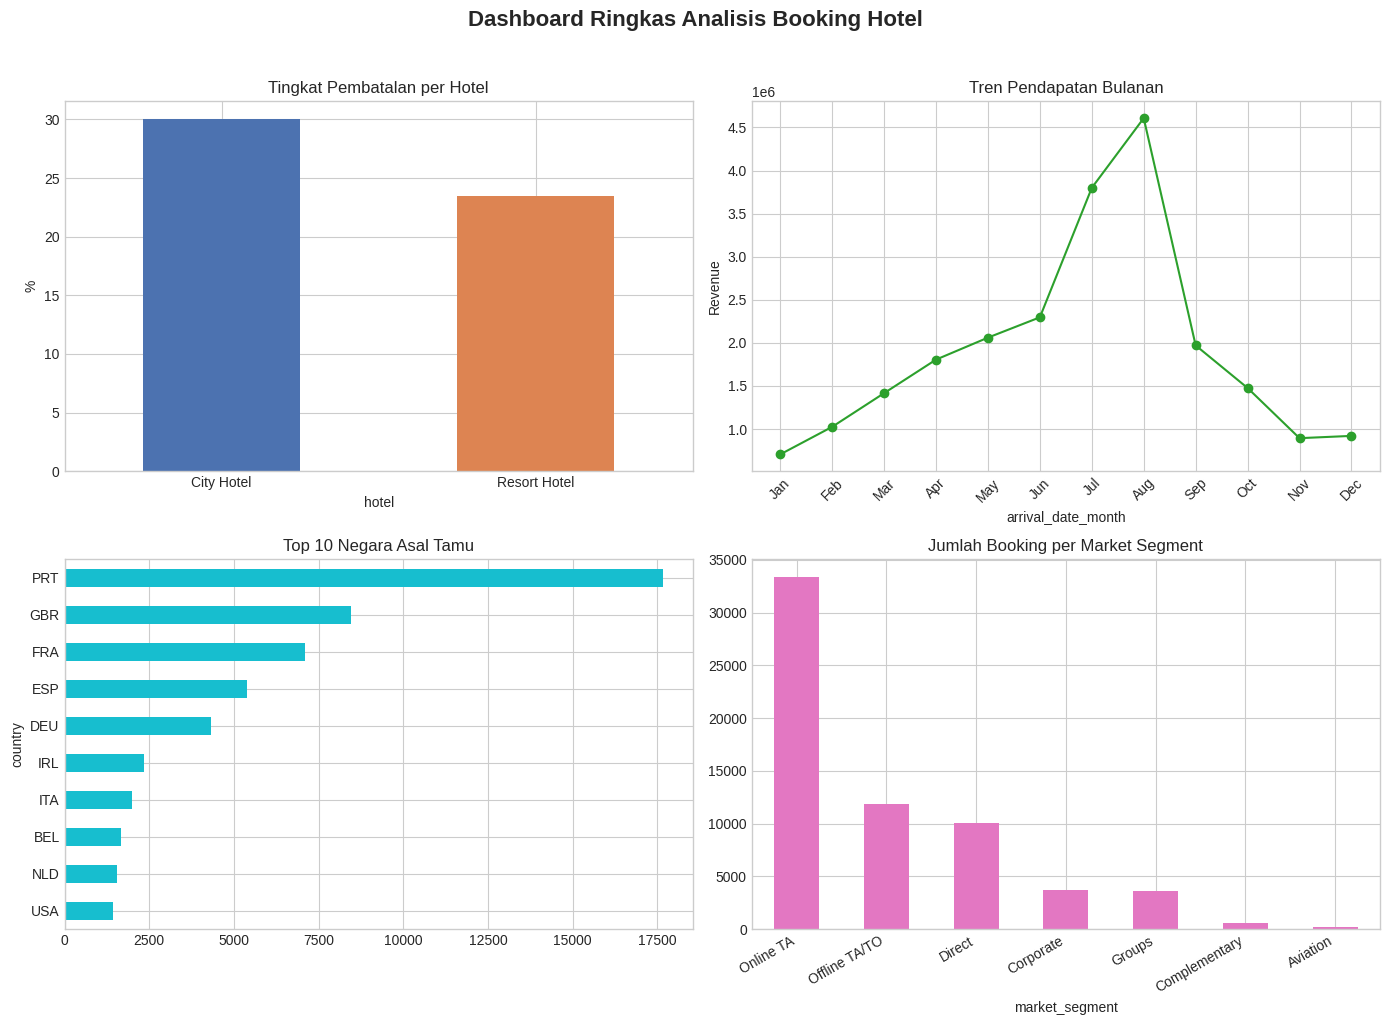

In [ ]:
# Cell 12: Dashboard Ringkas
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Dashboard Ringkas Analisis Booking Hotel', fontsize=16, fontweight='bold', y=1.02)

# (0,0) Cancel rate
cancel_by_hotel.plot(kind='bar', color=['#4C72B0', '#DD8452'], ax=axes[0,0])
axes[0,0].set_title('Tingkat Pembatalan per Hotel')
axes[0,0].set_ylabel('%')
axes[0,0].set_xticklabels(axes[0,0].get_xticklabels(), rotation=0)

# (0,1) Monthly revenue
monthly_rev.plot(kind='line', marker='o', color='#2ca02c', ax=axes[0,1])
axes[0,1].set_title('Tren Pendapatan Bulanan')
axes[0,1].set_ylabel('Revenue')
axes[0,1].set_xticks(range(12))
axes[0,1].set_xticklabels([m[:3] for m in month_order], rotation=45)

# (1,0) Top countries
top_c.plot(kind='barh', color='#17becf', ax=axes[1,0])
axes[1,0].set_title('Top 10 Negara Asal Tamu')
axes[1,0].invert_yaxis()

# (1,1) Market segment
seg = df_ok['market_segment'].value_counts()
seg.plot(kind='bar', color='#e377c2', ax=axes[1,1])
axes[1,1].set_title('Jumlah Booking per Market Segment')
axes[1,1].set_xticklabels(axes[1,1].get_xticklabels(), rotation=30, ha='right')

plt.tight_layout()
plt.show()

In [ ]:
# Cell 13: Laporan Rekomendasi Bisnis (200–300 kata)
print("="*60)
print("LAPORAN REKOMENDASI BISNIS")
print("="*60)

rekomendasi = """
Berdasarkan analisis 87.394 booking hotel (setelah pembersihan duplikat dan missing value) di Portugal tahun 2015–2017, ditemukan tingkat pembatalan keseluruhan 27,5%, dengan City Hotel lebih tinggi daripada Resort Hotel. Pendapatan (proxy ADR × malam menginap) memuncak di musim panas (Juli–Agustus) dan menurun tajam pada November–Januari. Portugal menjadi negara asal tamu terbesar, diikuti Inggris, Prancis, Spanyol, dan Jerman. Market segment Online TA mendominasi volume, sementara channel Direct masih relatif kecil.

Outlier ADR ekstrem (hingga €5.400) terdeteksi melalui aturan IQR (batas atas ≈ €227). Sebagian besar outlier kemungkinan error input data atau kasus khusus yang perlu divalidasi. Distribusi lead time sangat miring ke kanan; booking dengan lead time panjang cenderung memiliki risiko pembatalan lebih tinggi.

Rekomendasi utama kepada manajemen:
1. Turunkan cancellation rate dengan menerapkan deposit non-refundable atau free-cancel window terbatas, khususnya untuk booking lead time > 60 hari di City Hotel dan Online TA.
2. Rancang paket promosi off-season (November–Januari) berupa long-stay, corporate rate, atau event lokal agar pendapatan lebih merata.
3. Perkuat channel Direct melalui loyalty program, best-rate guarantee, dan SEO website hotel untuk mengurangi ketergantungan pada OTA dan meningkatkan margin.
4. Perbaiki kualitas data: audit booking dengan ADR ekstrem dan cegah input nilai negatif di sistem.
5. Pertahankan fokus pemasaran pada pasar Eropa inti (PRT, GBR, FRA, ESP, DEU) sambil menguji ekspansi terbatas ke pasar emerging.

Implementasi rekomendasi di atas diharapkan dapat menekan tingkat pembatalan, meratakan pendapatan sepanjang tahun, dan meningkatkan profitabilitas hotel secara keseluruhan.
"""

print(rekomendasi)
print(f"\nJumlah kata: {len(rekomendasi.split())} kata")
print("\n" + "="*60)
print("SELESAI – Semua kriteria proyek telah dipenuhi.")
print("="*60)

LAPORAN REKOMENDASI BISNIS

Berdasarkan analisis 87.394 booking hotel (setelah pembersihan duplikat dan missing value) di Portugal tahun 2015–2017, ditemukan tingkat pembatalan keseluruhan 27,5%, dengan City Hotel lebih tinggi daripada Resort Hotel. Pendapatan (proxy ADR × malam menginap) memuncak di musim panas (Juli–Agustus) dan menurun tajam pada November–Januari. Portugal menjadi negara asal tamu terbesar, diikuti Inggris, Prancis, Spanyol, dan Jerman. Market segment Online TA mendominasi volume, sementara channel Direct masih relatif kecil.

Outlier ADR ekstrem (hingga €5.400) terdeteksi melalui aturan IQR (batas atas ≈ €227). Sebagian besar outlier kemungkinan error input data atau kasus khusus yang perlu divalidasi. Distribusi lead time sangat miring ke kanan; booking dengan lead time panjang cenderung memiliki risiko pembatalan lebih tinggi.

Rekomendasi utama kepada manajemen:
1. Turunkan cancellation rate dengan menerapkan deposit non-refundable atau free-cancel window terbat